# Week 11 Contest: Predict the Failures

**IST 707 | In-class machine learning contest | Groups of 3 to 4**

A factory has 40 anonymised sensor columns (`f01` to `f40`) from machines that log a reading every few minutes.
For every row, `label = 1` means the machine **failed within the next 24 hours**. Your job is to predict that on rows you
haven't seen yet.

You have no column dictionary, no domain expert and no second chance at the hidden labels. You do have everything
from Weeks 1 to 10.

## Rules

| | |
|---|---|
| **Metric** | **Macro F1** on hard 0/1 predictions (average of the F1 for class 0 and class 1) |
| **Submissions** | **3 per round** per group. Extras are ignored. Choose carefully. |
| **Leaderboard** | Shows a score on a *public* 30% of the test rows. Your **final score** uses the other, *private* 70%. |
| **Rows are ordered by `id`** | `id` is time. The test rows come *after* the training rows. |
| **Tools** | Anything you like. Be ready to explain every choice you make. |

## Schedule

| Time | |
|---|---|
| 0:00 | Rules, data walkthrough, form groups |
| 0:15 to 0:55 | **Round 1** |
| 0:55 | Leaderboard and break |
| 1:05 to 1:55 | **Round 2** (something changes) |
| 1:55 | Break |
| 2:05 to 2:25 | Final submission window |
| 2:25 to 2:45 | Private scores revealed. Each group explains what mattered. |

## How you are graded

- **50%** final private-set score
- **30%** your explanation: what did you find, why did it help, what didn't work? Be specific. "We used XGBoost" is not an answer.
- **20%** improvement between your Round 1 and final scores

A group with a lower score and a clear, correct explanation beats a group with a higher score that can't say why.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix

GROUP_NAME = "Tyler-Mrgaj"      # <- your group's name (letters, numbers and dashes)
DATA_DIR = "data/"     # <- folder containing the .csv.gz files (use "." on Colab after uploading)

Matplotlib is building the font cache; this may take a moment.


## 2. Load the data

In [2]:
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test_r1 = pd.read_csv(f"{DATA_DIR}/test_round1.csv")

print("train:", train.shape, "  test_round1:", test_r1.shape)
train.head()

train: (300000, 42)   test_round1: (100000, 41)


,id,f01,f02,f03,f04,f05,f06,f07,f08,f09,...,f32,f33,f34,f35,f36,f37,f38,f39,f40,label
0,0,3.56152,-0.074170,NaN,221.3950,-13741.20,2.667830,-0.139325,0.148469,-0.000410,...,NaN,-43.9552,0.071623,NaN,2.946890,NaN,-143984.0,NaN,NaN,0
1,1,3.76555,-0.079199,0.614575,200.2110,6403.91,NaN,-0.118521,0.167538,-0.003510,...,NaN,-36.8531,0.314930,80077.400,0.954271,NaN,NaN,563963.0,-0.085834,0
2,2,9.02549,0.218414,NaN,278.9230,-10619.90,0.524069,0.221206,0.291940,-0.011195,...,NaN,-39.1823,-0.057419,-127381.000,8.884460,0.141487,NaN,1415800.0,-0.021034,0
3,3,47.24730,-0.146086,0.628576,-54.1278,-19536.10,NaN,0.013726,0.141845,-0.030093,...,9782.86,-17.7097,-1.104030,6281.830,NaN,0.108336,209311.0,758097.0,0.002493,1
4,4,35.62250,0.138242,-3.720960,185.8080,-15044.40,0.564511,0.063683,0.149048,-0.018470,...,21395.10,-35.6907,-0.421117,917.632,8.698640,NaN,60725.0,NaN,0.512969,0


## 3. First look

Take a few minutes as a group **before** fitting anything. Some things worth checking:

- How balanced is the label? What would a model that always predicts `0` score on accuracy? On macro F1?
- What do the columns look like? Ranges, missing values, odd values.
- Do any columns change over `id`?
- Are there groups of rows (machine types) hiding in the data? You have a whole week of clustering behind you.

In [3]:
print("Failure rate:", train["label"].mean().round(4))
print("Accuracy of 'always 0':", (1 - train["label"].mean()).round(4))
print("Macro F1 of 'always 0':", round(f1_score(train["label"], np.zeros(len(train)), average="macro"), 4))

Failure rate: 0.0584
Accuracy of 'always 0': 0.9416
Macro F1 of 'always 0': 0.485


In [4]:
features = [c for c in train.columns if c.startswith("f")]
train[features].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2)

,count,mean,std,min,50%,max
f01,249962.0,36.66,37.83,-1251.47,36.46,9.837330e+03
f02,280007.0,-0.05,9.44,-999.00,0.04,2.926000e+01
f03,209313.0,-0.92,10.08,-999.00,-0.56,3.777300e+02
f04,298677.0,197.02,227.62,-999.00,228.05,3.641400e+04
f05,298610.0,-14497.69,21501.80,-4215520.00,-14385.85,2.060880e+05
f06,275378.0,1.16,6.50,-999.00,1.19,2.773000e+02
f07,298652.0,-0.04,6.34,-999.00,-0.00,2.084000e+01
f08,298652.0,0.16,7.32,-999.00,0.17,1.893700e+02
f09,298604.0,-0.06,7.08,-999.00,-0.01,3.630000e+00
f10,270295.0,0.40,7.46,-999.00,0.45,1.090700e+02


In [5]:
train[features].isna().mean().sort_values(ascending=False).head(10).round(3)

f03    0.302
f32    0.297
f37    0.296
f20    0.275
f36    0.264
f40    0.259
f38    0.247
f17    0.215
f25    0.177
f24    0.169
dtype: float64

## 4. Baseline

This is a deliberately plain model: all the columns as they are, default settings. **Every group starts here. This
is not a good score. It is the bar to beat.**

> **Validation hint:** the test rows are *later in time* than the training rows. Think about whether a random
> train/test split is the right way to estimate your score. The baseline below splits by time.

In [6]:
cut = int(len(train) * 0.8)
fit_part, val_part = train.iloc[:cut], train.iloc[cut:]

base = HistGradientBoostingClassifier(random_state=0)
base.fit(fit_part[features], fit_part["label"])

val_pred = base.predict(val_part[features])
print("Validation macro F1:", round(f1_score(val_part["label"], val_pred, average="macro"), 4))
print(classification_report(val_part["label"], val_pred, digits=3))

Validation macro F1: 0.6804
              precision    recall  f1-score   support

           0      0.955     0.993     0.973     56408
           1      0.695     0.268     0.387      3592

    accuracy                          0.949     60000
   macro avg      0.825     0.630     0.680     60000
weighted avg      0.940     0.949     0.938     60000



## 5. Your turn

Add cells below. Ideas to get you going (none of them is a hint about what is actually in the data):

- Look at every column against `id` and against `label`.
- Look at where the model is wrong. Which kind of row does it miss?
- Is 0.5 the right cut-off for turning a probability into a 0/1 prediction?
- Does clustering the rows (K-Means, GMM) give you anything useful?
- Which of the 40 columns matter? Which are noise?

Keep a log of **what you tried and what happened**. You'll need it for the explanation part.

Default 0.50 threshold -> macro F1: 0.6804
Best threshold 0.23     -> macro F1: 0.7086


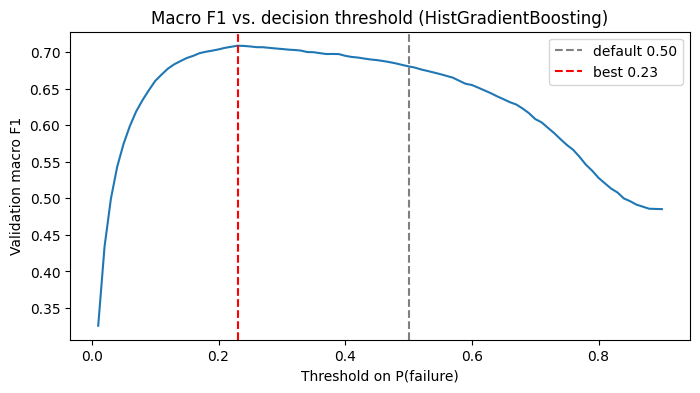

              precision    recall  f1-score   support

           0      0.963     0.973     0.968     56408
           1      0.492     0.413     0.449      3592

    accuracy                          0.939     60000
   macro avg      0.727     0.693     0.709     60000
weighted avg      0.935     0.939     0.937     60000

[[54874  1534]
 [ 2107  1485]]


In [7]:
# --- Threshold tuning for the HistGradientBoostingClassifier ---
# The model's .predict() uses a 0.5 cut-off on P(failure). With only ~6% failures that is too high,
# so we sweep thresholds on the time-based validation set and keep the one with the best macro F1.

val_proba = base.predict_proba(val_part[features])[:, 1]   # P(label = 1) for each validation row
y_val = val_part["label"].values

thresholds = np.arange(0.01, 0.91, 0.01)
macro_f1s = [f1_score(y_val, (val_proba >= t).astype(int), average="macro") for t in thresholds]

best_idx = int(np.argmax(macro_f1s))
best_threshold = thresholds[best_idx]
print(f"Default 0.50 threshold -> macro F1: {f1_score(y_val, (val_proba >= 0.5).astype(int), average='macro'):.4f}")
print(f"Best threshold {best_threshold:.2f}     -> macro F1: {macro_f1s[best_idx]:.4f}")

# Plot macro F1 against threshold so you can see how sharp or flat the peak is
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, macro_f1s)
ax.axvline(0.5, color="gray", linestyle="--", label="default 0.50")
ax.axvline(best_threshold, color="red", linestyle="--", label=f"best {best_threshold:.2f}")
ax.set_xlabel("Threshold on P(failure)")
ax.set_ylabel("Validation macro F1")
ax.set_title("Macro F1 vs. decision threshold (HistGradientBoosting)")
ax.legend()
plt.show()

# Full report at the chosen threshold
val_pred_tuned = (val_proba >= best_threshold).astype(int)
print(classification_report(y_val, val_pred_tuned, digits=3))
print(confusion_matrix(y_val, val_pred_tuned))

# To use it on the test set:  preds = (base.predict_proba(test_r1[features])[:, 1] >= best_threshold).astype(int)

In [9]:
# --- Random forest: untuned baseline, then grid search, all scored at best_threshold ---
# RandomForestClassifier handles NaN natively in scikit-learn >= 1.4, so no imputer is needed.
# Kept small for time: 100 trees, each on a random 50% of rows (max_samples), and a 3-combination grid.
# Expect roughly 3-5 minutes for the whole cell.
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit

X_fit, y_fit = fit_part[features], fit_part["label"]
X_val, y_val = val_part[features], val_part["label"].values

def threshold_macro_f1(estimator, X, y):
    """Scorer: macro F1 after cutting P(failure) at best_threshold instead of 0.5."""
    proba = estimator.predict_proba(X)[:, 1]
    return f1_score(y, (proba >= best_threshold).astype(int), average="macro")

RF_FIXED = dict(n_estimators=100, max_samples=0.5, n_jobs=-1, random_state=0)

# 1) Untuned random forest (default tree settings)
rf_base = RandomForestClassifier(**RF_FIXED)
rf_base.fit(X_fit, y_fit)
rf_base_score = threshold_macro_f1(rf_base, X_val, y_val)
print(f"Untuned RF   @ threshold {best_threshold:.2f} -> validation macro F1: {rf_base_score:.4f}")

# 2) Grid search on the same time-based split (train on first 80%, score on last 20%).
#    PredefinedSplit keeps the search honest: no random folds that mix later rows into training.
X_all = pd.concat([X_fit, X_val])
y_all = np.concatenate([y_fit.values, y_val])
split = PredefinedSplit(np.r_[np.full(len(X_fit), -1), np.zeros(len(X_val), dtype=int)])

# min_samples_leaf mattered most in the earlier partial run: bigger leaves = less overfitting
param_grid = {"min_samples_leaf": [10, 25, 50]}
grid = GridSearchCV(
    RandomForestClassifier(**RF_FIXED),
    param_grid,
    scoring=threshold_macro_f1,
    cv=split,
    refit=False,      # refitting would train on the validation rows too; we refit on fit_part below
    verbose=2,
)
grid.fit(X_all, y_all)

results = pd.DataFrame(grid.cv_results_)[["params", "mean_test_score"]].sort_values("mean_test_score", ascending=False)
print(results.to_string(index=False))
print("Best params:", grid.best_params_)

# 3) Refit the best settings on the training part only and score on validation
rf_tuned = RandomForestClassifier(**RF_FIXED, **grid.best_params_)
rf_tuned.fit(X_fit, y_fit)
rf_tuned_proba = rf_tuned.predict_proba(X_val)[:, 1]
rf_tuned_pred = (rf_tuned_proba >= best_threshold).astype(int)

print(f"\nUntuned RF @ {best_threshold:.2f}: {rf_base_score:.4f}")
print(f"Tuned RF   @ {best_threshold:.2f}: {f1_score(y_val, rf_tuned_pred, average='macro'):.4f}")
print(classification_report(y_val, rf_tuned_pred, digits=3))
print(confusion_matrix(y_val, rf_tuned_pred))

# The threshold was tuned for HistGradientBoosting; RF probabilities are scaled differently,
# so check whether a different cut-off suits the tuned forest better.
rf_f1s = [f1_score(y_val, (rf_tuned_proba >= t).astype(int), average="macro") for t in thresholds]
print(f"Tuned RF's own best threshold: {thresholds[int(np.argmax(rf_f1s))]:.2f} -> macro F1 {max(rf_f1s):.4f}")

Untuned RF   @ threshold 0.23 -> validation macro F1: 0.6976
Fitting 1 folds for each of 3 candidates, totalling 3 fits
[CV] END ................................min_samples_leaf=10; total time=  16.4s
[CV] END ................................min_samples_leaf=25; total time=  16.9s
[CV] END ................................min_samples_leaf=50; total time=  15.8s
                  params  mean_test_score
{'min_samples_leaf': 10}         0.701834
{'min_samples_leaf': 25}         0.700366
{'min_samples_leaf': 50}         0.699194
Best params: {'min_samples_leaf': 10}

Untuned RF @ 0.23: 0.6976
Tuned RF   @ 0.23: 0.7018
              precision    recall  f1-score   support

           0      0.960     0.979     0.970     56408
           1      0.530     0.367     0.434      3592

    accuracy                          0.943     60000
   macro avg      0.745     0.673     0.702     60000
weighted avg      0.935     0.943     0.938     60000

[[55239  1169]
 [ 2273  1319]]
Tuned RF's own best 

In [10]:
# --- XGBoost: untuned baseline, then grid search, all scored at best_threshold ---
# Reuses X_fit, y_fit, X_val, y_val, X_all, y_all, split and threshold_macro_f1 from the random forest cell above.
# XGBoost handles NaN natively (it learns which way missing values should go at each split).
# Runtime: each fit takes seconds, not minutes, so this is much faster than the random forest search.
from xgboost import XGBClassifier

# 1) Untuned XGBoost (library defaults)
xgb_base = XGBClassifier(n_jobs=-1, random_state=0)
xgb_base.fit(X_fit, y_fit)
xgb_base_score = threshold_macro_f1(xgb_base, X_val, y_val)
print(f"Untuned XGB  @ threshold {best_threshold:.2f} -> validation macro F1: {xgb_base_score:.4f}")

# 2) Grid search on the same time-based split (24 combinations)
xgb_grid_params = {
    "max_depth": [3, 5, 7],              # tree depth: shallower = less overfitting
    "learning_rate": [0.05, 0.1],        # smaller steps generalise better but need more trees
    "min_child_weight": [1, 10],         # minimum weight per leaf, like min_samples_leaf in RF
    "subsample": [0.8, 1.0],             # fraction of rows used per tree
}
xgb_grid = GridSearchCV(
    XGBClassifier(n_estimators=300, colsample_bytree=0.8, n_jobs=-1, random_state=0),
    xgb_grid_params,
    scoring=threshold_macro_f1,
    cv=split,
    refit=False,      # refit on fit_part only below, so validation rows stay unseen
    verbose=1,
)
xgb_grid.fit(X_all, y_all)

xgb_results = pd.DataFrame(xgb_grid.cv_results_)[["params", "mean_test_score"]].sort_values("mean_test_score", ascending=False)
print(xgb_results.head(10).to_string(index=False))
print("Best params:", xgb_grid.best_params_)

# 3) Refit the best settings on the training part only and score on validation
xgb_tuned = XGBClassifier(n_estimators=300, colsample_bytree=0.8, n_jobs=-1, random_state=0, **xgb_grid.best_params_)
xgb_tuned.fit(X_fit, y_fit)
xgb_tuned_proba = xgb_tuned.predict_proba(X_val)[:, 1]
xgb_tuned_pred = (xgb_tuned_proba >= best_threshold).astype(int)

print(f"\nUntuned XGB @ {best_threshold:.2f}: {xgb_base_score:.4f}")
print(f"Tuned XGB   @ {best_threshold:.2f}: {f1_score(y_val, xgb_tuned_pred, average='macro'):.4f}")
print(classification_report(y_val, xgb_tuned_pred, digits=3))
print(confusion_matrix(y_val, xgb_tuned_pred))

# The threshold came from HistGradientBoosting; check whether the tuned XGBoost prefers a different cut-off.
xgb_f1s = [f1_score(y_val, (xgb_tuned_proba >= t).astype(int), average="macro") for t in thresholds]
print(f"Tuned XGB's own best threshold: {thresholds[int(np.argmax(xgb_f1s))]:.2f} -> macro F1 {max(xgb_f1s):.4f}")

Untuned XGB  @ threshold 0.23 -> validation macro F1: 0.7143
Fitting 1 folds for each of 24 candidates, totalling 24 fits
                                                                           params  mean_test_score
 {'learning_rate': 0.1, 'max_depth': 5, 'min_child_weight': 10, 'subsample': 0.8}         0.727002
  {'learning_rate': 0.1, 'max_depth': 5, 'min_child_weight': 1, 'subsample': 0.8}         0.726678
 {'learning_rate': 0.05, 'max_depth': 7, 'min_child_weight': 1, 'subsample': 0.8}         0.726176
 {'learning_rate': 0.1, 'max_depth': 5, 'min_child_weight': 10, 'subsample': 1.0}         0.726093
  {'learning_rate': 0.1, 'max_depth': 5, 'min_child_weight': 1, 'subsample': 1.0}         0.726025
{'learning_rate': 0.05, 'max_depth': 7, 'min_child_weight': 10, 'subsample': 0.8}         0.726011
  {'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 1, 'subsample': 0.8}         0.725744
  {'learning_rate': 0.1, 'max_depth': 7, 'min_child_weight': 1, 'subsample': 1.0}     

In [ ]:
# --- Improved XGBoost: f12 shift fix + f15 x f20 interaction + more, smaller boosting steps ---
# Finding 1: f12 jumps from a median of ~133 to ~310 at id 150,000 (halfway through train) and stays there in test.
#   The spread changes too (IQR ~24 -> ~43), so we standardise f12 separately in each period:
#   (value - period median) / period IQR. Now "high f12" means the same thing before and after the jump.
# Finding 2: f15 and f20 are useless on their own (flat failure rate) but matter together: failures are ~10% when
#   they have the same sign and ~1.5% when the signs differ. Trees only approximate this with many splits,
#   so we give the model the product f15*f20 and a same-sign flag directly.
# Validation: tuned XGB 0.7270 -> 0.7313 with the f12 fix + 1000 trees -> ~0.734 with the f15/f20 features
#   (averaged over 3 time periods; the gain showed up in every period). Retuning with the new features: no gain.
# Runtime: well under a minute.

F12_SHIFT_ID = 150_000   # found by plotting the median of f12 over id

def f12_stats(df):
    """Median and IQR of f12 before and after the shift, learned from training rows only."""
    stats = {}
    for name, part in [("before", df[df["id"] < F12_SHIFT_ID]), ("after", df[df["id"] >= F12_SHIFT_ID])]:
        v = part["f12"]
        stats[name] = (v.median(), v.quantile(0.75) - v.quantile(0.25))
    return stats

def prepare_features(df, stats):
    """Return a copy of df[features] with f12 standardised per period and the f15 x f20 interaction added."""
    X = df[features].copy()
    for name, mask in [("before", df["id"] < F12_SHIFT_ID), ("after", df["id"] >= F12_SHIFT_ID)]:
        med, iqr = stats[name]
        X.loc[mask, "f12"] = (X.loc[mask, "f12"] - med) / iqr
    # Both f15 and f20 are centred on 0 (median ~0), so the sign of the product says whether they agree
    X["f15_x_f20"] = df["f15"] * df["f20"]
    both_present = df["f15"].notna() & df["f20"].notna()
    X["f15_f20_same_sign"] = (np.sign(df["f15"]) == np.sign(df["f20"])).astype(float).where(both_present)  # NaN if either missing
    return X

XGB_FINAL = dict(n_estimators=1000, learning_rate=0.03, max_depth=5, min_child_weight=10,
                 subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=0)

# 1) Validate on the same time-based split (stats come from fit_part only, so nothing leaks from validation)
stats_fit = f12_stats(fit_part)
xgb_fix = XGBClassifier(**XGB_FINAL)
xgb_fix.fit(prepare_features(fit_part, stats_fit), fit_part["label"])
fix_proba = xgb_fix.predict_proba(prepare_features(val_part, stats_fit))[:, 1]

fix_f1s = [f1_score(y_val, (fix_proba >= t).astype(int), average="macro") for t in thresholds]
final_threshold = thresholds[int(np.argmax(fix_f1s))]
print(f"Tuned XGB (previous cell) @ {best_threshold:.2f}: {f1_score(y_val, xgb_tuned_pred, average='macro'):.4f}")
print(f"Improved XGB @ its best threshold {final_threshold:.2f}: {max(fix_f1s):.4f}")
print(classification_report(y_val, (fix_proba >= final_threshold).astype(int), digits=3))

# 2) Retrain on ALL training rows for the submission. The last 20% are the most recent rows and are
#    closest in time to the test set, so leaving them out of the final model would waste them.
stats_all = f12_stats(train)
xgb_full = XGBClassifier(**XGB_FINAL)
xgb_full.fit(prepare_features(train, stats_all), train["label"])

test_proba = xgb_full.predict_proba(prepare_features(test_r1, stats_all))[:, 1]
final_preds = (test_proba >= final_threshold).astype(int)
print(f"Test rows predicted as failures: {final_preds.mean():.1%}  (train failure rate: {train['label'].mean():.1%})")

# 3) Write the submission file (run the make_submission cell in Part 6 first if you haven't yet)
make_submission(test_r1, final_preds, GROUP_NAME, "round1")

## 6. Making a submission

In [12]:
import os, re
from datetime import datetime

def make_submission(test_df, preds, group, round_name, out_dir="my_submissions"):
    """Validate predictions and write  <group>__<round>__<HHMMSS>.csv  ready to hand in."""
    preds = np.asarray(preds).astype(int)
    assert len(preds) == len(test_df), f"Expected {len(test_df)} predictions, got {len(preds)}"
    assert set(np.unique(preds)) <= {0, 1}, "Predictions must be hard 0/1 labels, not probabilities"
    group = re.sub(r"[^A-Za-z0-9]+", "-", group).strip("-")
    os.makedirs(out_dir, exist_ok=True)
    path = f"{out_dir}/{group}__{round_name}__{datetime.now():%H%M%S}.csv"
    pd.DataFrame({"id": test_df["id"].values, "pred": preds}).to_csv(path, index=False)
    print(f"Wrote {path}  ({preds.mean():.1%} predicted positive)")
    return path

In [ ]:
# Example: submit the baseline. Replace `base` and the features with your own model and pipeline.
preds = base.predict(test_r1[features])
make_submission(test_r1, preds, GROUP_NAME, "round1")

Hand the file from `my_submissions/` to your instructor (upload it to the class submission folder).
You have **5 submissions in Round 1**. The baseline counts as one if you submit it.